# How the land changed over 2021, month by month

The best trained model maps every month of each test region from radar alone; this counts what share of the area each class covers, month by month.

In [14]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks/ sits one level below the project
sys.path.insert(0, str(ROOT))

import csv
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
from tqdm import tqdm

import config
from training.model import build_model
from training.build_dataset import radar_channels   # the exact scaling the model was trained on


def progress(iterable=None, **kw):
    """Plain text progress bar - shows in every notebook viewer."""
    return tqdm(iterable, file=sys.stdout, ncols=120, **kw)


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.5.1+cu121 | device: cuda


## Settings

Which trained run to use, which regions to map, and how strict to be about calling a change real.

In [15]:
RUN = "auto"                 # "auto" = best VALIDATION score of the 9-class runs; or "unet16", "deeplab", "segformer"
REGIONS = config.TEST_AOIS   # never trained on - a training region only repeats the yearly label it memorised
STRIDE = 64                  # tiles overlap by half and are averaged, so there are no seams at tile edges
BATCH = 32
NOISE_CLASS = 2              # built-up: a city does not grow or vanish within a year, so its wobble is noise
MIN_SHARE = 1.0              # %, classes below this in every month are left off the charts
MIN_DW_COVER = 0.5           # Dynamic World months that saw less than half the box are left out of the check
DW_CSV = config.OUTPUTS / "dw_monthly_2021.csv"   # from labelling/gee/export_dw_monthly.js

MONTHS = [f"{config.YEAR}-{m:02d}" for m in range(1, 13)]
SHORT = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
CLASS_IDS = list(range(1, config.NUM_CLASSES))
# Dynamic World's own colours, in our class order (0 = not mapped, white)
COLOURS = ["#ffffff", "#419bdf", "#c4281b", "#397d49", "#e49635",
           "#88b053", "#a59b8f", "#dfc35a", "#7a87c6", "#b39fe1"]
print("regions:", ", ".join(REGIONS))

regions: lake_geneva, tokyo, congo, kansas, ireland, death_valley, mannheim


## The model

Takes the run with the best validation score - chosen on validation, never on test, so the test regions stay an honest check.

In [16]:
def pick_run(run):
    if run != "auto":
        return run
    scored = []
    for path in config.OUTPUTS.glob("*_result.json"):
        r = json.loads(path.read_text())
        if str(r.get("recipe", "")).startswith("nine-classes"):
            scored.append((r["val"]["mean_iou"], path.stem.replace("_result", "")))
    if not scored:
        raise SystemExit("No 9-class run has finished yet - train with the 02 notebooks first.")
    for value, name in sorted(scored, reverse=True):
        print(f"   {name:<10} validation mIoU {100 * value:.1f}%")
    return max(scored)[1]


RUN_NAME = pick_run(RUN)
saved = torch.load(config.WEIGHTS / f"{RUN_NAME}_best.pt", map_location=DEVICE, weights_only=False)
if saved["kwargs"].get("classes") != config.NUM_CLASSES:
    raise SystemExit(f"{RUN_NAME}_best.pt predicts {saved['kwargs'].get('classes')} outputs, "
                     f"config has {config.NUM_CLASSES} - it is from an older class list.")
net = build_model(saved["model"], **saved["kwargs"]).to(DEVICE).eval()
net.load_state_dict(saved["state"])
print(f"\nusing {RUN_NAME} ({saved['model']}), best epoch {saved['epoch']}, "
      f"validation mIoU {100 * saved['val_miou']:.1f}%")

   segformer  validation mIoU 51.3%
   deeplab    validation mIoU 49.0%
   unet16     validation mIoU 42.1%

using segformer (segformer), best epoch 40, validation mIoU 51.3%


## Map every month

Each month's radar goes through the model on overlapping tiles; the shares are counted only over ground the radar saw in all 12 months, so every month is measured on the same area.

In [17]:
def starts(total, tile=config.TILE_PX, stride=STRIDE):
    """Tile positions along one axis, the last one flush with the edge."""
    s = list(range(0, total - tile + 1, stride))
    if s[-1] != total - tile:
        s.append(total - tile)
    return s


@torch.no_grad()
def predict(path):
    """One month's radar -> class map (ids 1-9), plus where the radar saw."""
    x, seen = radar_channels(path)
    H, W = seen.shape
    T = config.TILE_PX
    score = np.zeros((config.NUM_CLASSES - 1, H, W), np.float32)
    spots = [(r, c) for r in starts(H) for c in starts(W)]
    for i in range(0, len(spots), BATCH):
        chunk = spots[i:i + BATCH]
        batch = torch.from_numpy(np.stack([x[:, r:r + T, c:c + T] for r, c in chunk])).to(DEVICE)
        prob = torch.softmax(net(batch)[:, 1:], dim=1).cpu().numpy()   # class 0 is never an answer
        for (r, c), p in zip(chunk, prob):
            score[:, r:r + T, c:c + T] += p
    return (score.argmax(0) + 1).astype(np.uint8), seen


maps, shares, common_share = {}, {}, {}
for aoi in progress(REGIONS, desc="mapping regions", unit="region"):
    files = {config.month_of(p): p for p in sorted((config.S1_MONTHLY / aoi).glob("*.tif"))}
    missing = [m for m in MONTHS if m not in files]
    if missing:
        print(f"   {aoi}: no radar for {', '.join(missing)} - skipped")
        continue
    stack, seen_all = [], None
    for month in MONTHS:
        pred, seen = predict(files[month])
        stack.append(pred)
        seen_all = seen if seen_all is None else seen_all & seen
    stack = np.stack(stack)
    stack[:, ~seen_all] = 0
    maps[aoi] = stack
    common_share[aoi] = float(seen_all.mean())
    counted = stack[:, seen_all]                                   # (12, pixels seen every month)
    shares[aoi] = np.stack([np.bincount(m, minlength=config.NUM_CLASSES) for m in counted])
    shares[aoi] = 100 * shares[aoi] / max(counted.shape[1], 1)     # % per month, column = class id

for aoi in maps:
    print(f"   {aoi:<14} measured on {100 * common_share[aoi]:.0f}% of the box (seen in every month)")

mapping regions: 100%|████████████████████████████████████████████████████████████████| 7/7 [00:12<00:00,  1.72s/region]
   lake_geneva    measured on 100% of the box (seen in every month)
   tokyo          measured on 100% of the box (seen in every month)
   congo          measured on 100% of the box (seen in every month)
   kansas         measured on 95% of the box (seen in every month)
   ireland        measured on 98% of the box (seen in every month)
   death_valley   measured on 100% of the box (seen in every month)
   mannheim       measured on 100% of the box (seen in every month)


## The noise floor

Built-up cannot really change within a year, so however much the model's built-up share wanders from month to month is the model's own noise; a change smaller than that means nothing.

In [18]:
swing = {aoi: float(np.ptp(s[:, NOISE_CLASS])) for aoi, s in shares.items()}
cities = [aoi for aoi, s in shares.items() if s[:, NOISE_CLASS].mean() >= 5]   # enough city to measure
print(f"{'region':<14}{'built-up, mean':>16}{'swing over the year':>22}")
for aoi, s in shares.items():
    used = "" if aoi in cities else "   (too little city to measure)"
    print(f"{aoi:<14}{s[:, NOISE_CLASS].mean():>15.1f}%{swing[aoi]:>20.1f} pts{used}")
NOISE = float(np.median([swing[a] for a in cities])) if cities else max(swing.values())
print(f"\nnoise floor: {NOISE:.1f} percentage points")
print("A class whose share swings less than this over the year has not measurably changed.")

region          built-up, mean   swing over the year
lake_geneva              15.9%                 3.7 pts
tokyo                    88.4%                 1.5 pts
congo                     0.2%                 0.3 pts   (too little city to measure)
kansas                    1.8%                 2.8 pts   (too little city to measure)
ireland                   4.4%                 1.6 pts   (too little city to measure)
death_valley             31.5%                17.9 pts
mannheim                 39.9%                11.3 pts

noise floor: 7.5 percentage points
A class whose share swings less than this over the year has not measurably changed.


## Month by month

The share of each region covered by each class, every month of 2021.

In [19]:
def shown(aoi):
    return [c for c in CLASS_IDS if shares[aoi][:, c].max() >= MIN_SHARE]


for aoi in shares:
    print(f"\n{aoi}  (% of the area)")
    print(f"{'':<20}" + "".join(f"{m:>6}" for m in SHORT))
    for c in shown(aoi):
        print(f"{config.CLASSES[c]:<20}" + "".join(f"{v:>6.1f}" for v in shares[aoi][:, c]))


lake_geneva  (% of the area)
                       Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
water                 30.8  31.1  32.8  33.6  27.9  33.2  28.1  32.9  32.1  34.2  33.5  32.1
built-up              14.7  16.7  15.6  14.2  16.6  17.3  16.6  17.9  15.2  14.7  15.7  15.9
trees                 12.1  16.9  17.2  16.9  13.5  16.0  15.4   9.4  10.3  10.9  15.4  13.8
cropland              33.1  23.6  23.4  20.7  29.6  20.8  26.9  30.9  33.1  32.1  26.4  29.3
grass                  7.8   8.5   7.2   7.5  10.9   7.4  11.9   7.0   8.3   5.6   6.5   8.0
shrub & scrub          1.5   3.1   3.6   6.7   1.5   5.2   1.2   1.8   0.8   1.8   2.2   0.9

tokyo  (% of the area)
                       Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
water                 11.2   9.2   9.6   8.7   9.4   9.1  10.0  10.0   8.2   8.9  10.1   9.6
built-up              87.5  88.0  88.3  87.9  88.4  88.7  89.0  88.8  89.0  89.0  88.0  88.1
bare            

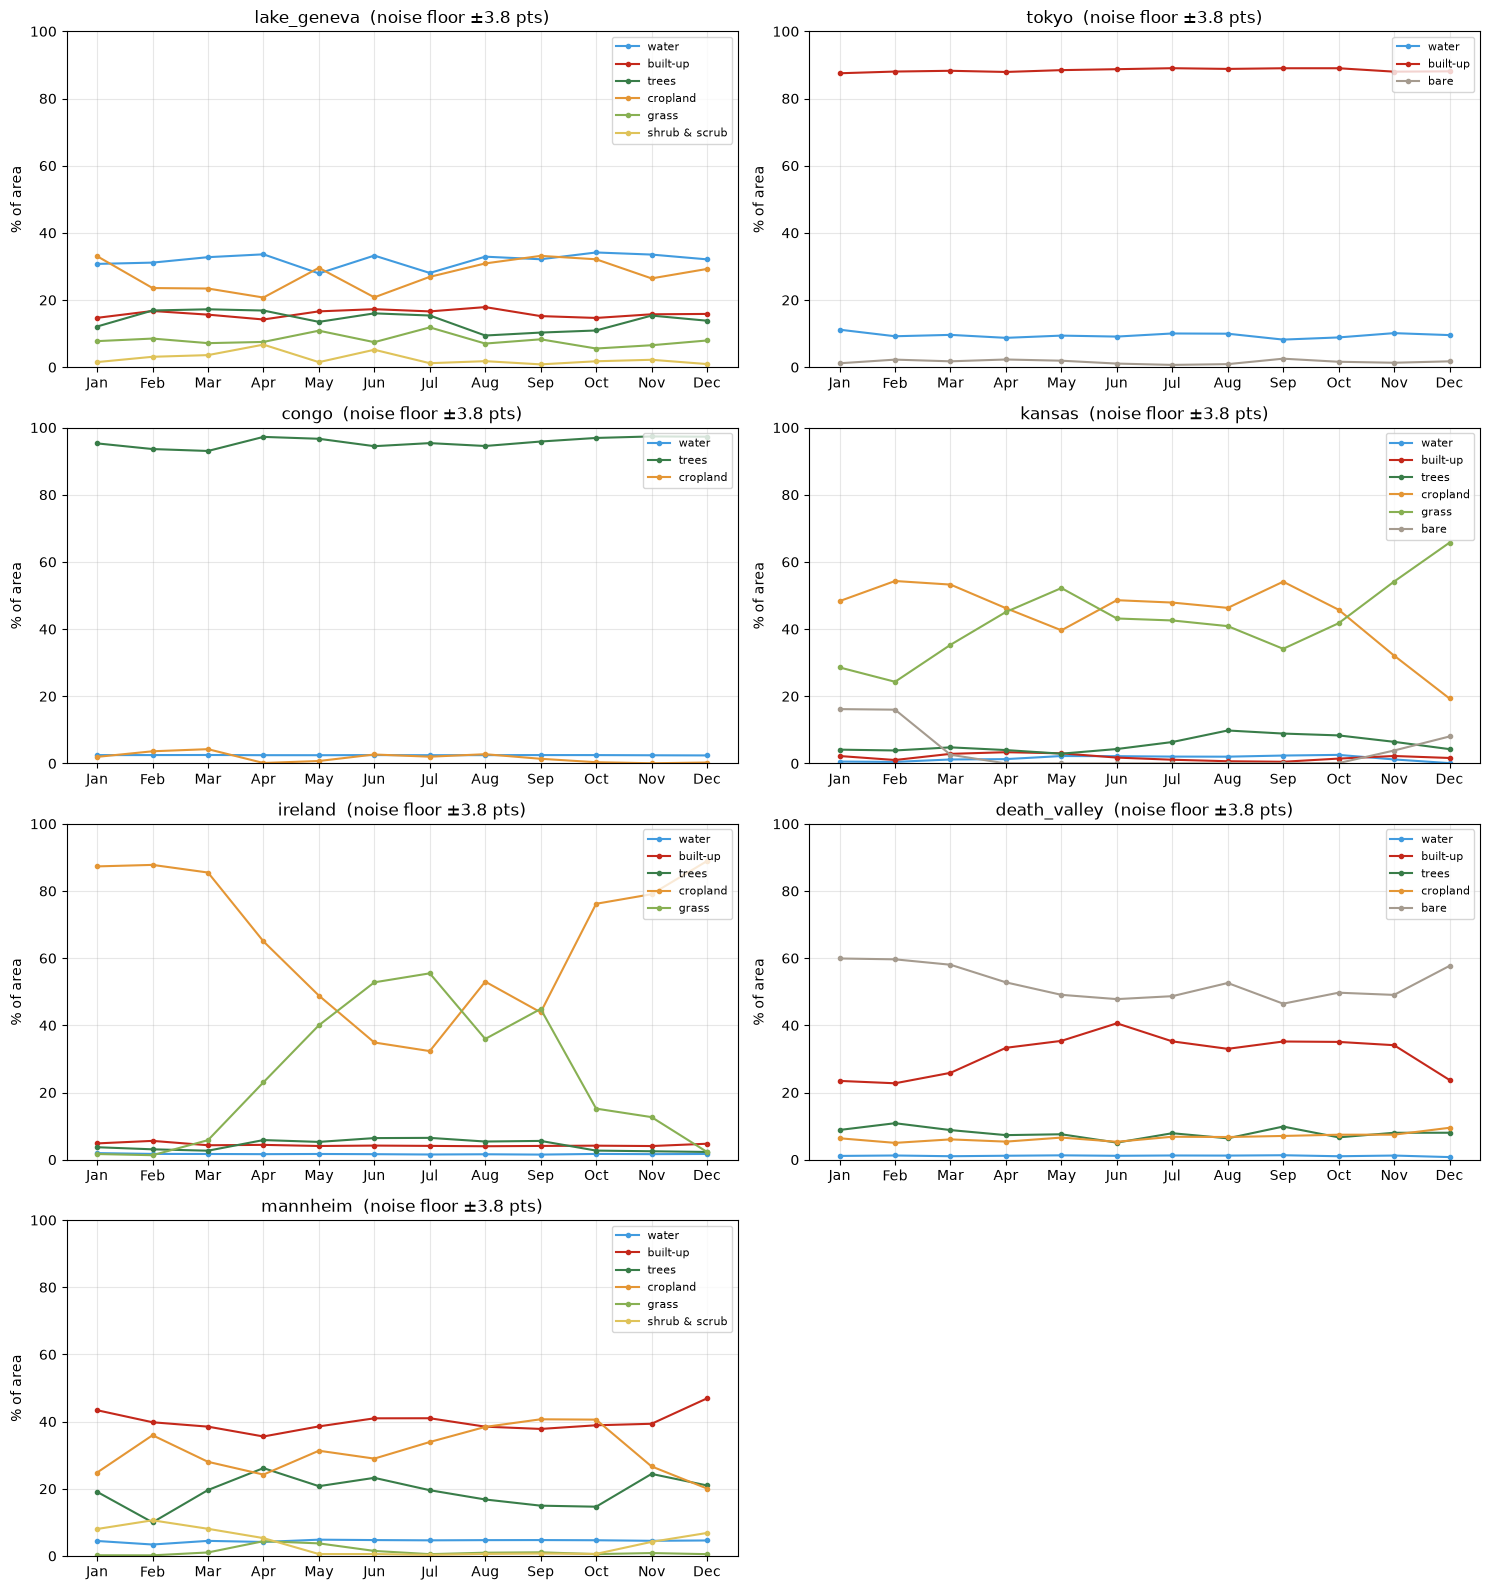

In [20]:
cols = 2
rows = int(np.ceil(len(shares) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), squeeze=False)
for ax, aoi in zip(axes.ravel(), shares):
    for c in shown(aoi):
        ax.plot(range(12), shares[aoi][:, c], marker="o", ms=3, color=COLOURS[c], label=config.CLASSES[c])
    ax.set_xticks(range(12)); ax.set_xticklabels(SHORT)
    ax.set_ylabel("% of area"); ax.set_ylim(0, 100); ax.grid(alpha=0.3)
    ax.set_title(f"{aoi}  (noise floor ±{NOISE / 2:.1f} pts)")
    ax.legend(fontsize=8, loc="upper right")
for ax in axes.ravel()[len(shares):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## By season

The same numbers averaged over three months - smoother, and the table to quote; in the southern hemisphere the seasons are reversed, and near the equator there are wet and dry seasons instead.

In [21]:
SEASONS = [("Dec-Feb", [12, 1, 2]), ("Mar-May", [3, 4, 5]), ("Jun-Aug", [6, 7, 8]), ("Sep-Nov", [9, 10, 11])]


def season_names(aoi):
    lat = config.AOIS[aoi]["centre"][1]
    if abs(lat) < 23.5:
        return ["", "", "", ""], "tropics - wet and dry seasons, not four"
    north = lat > 0
    names = ["winter", "spring", "summer", "autumn"] if north else ["summer", "autumn", "winter", "spring"]
    return names, ("northern" if north else "southern") + " hemisphere"


season_shares = {}
for aoi in shares:
    names, where = season_names(aoi)
    season_shares[aoi] = np.stack([shares[aoi][[m - 1 for m in months]].mean(0) for _, months in SEASONS])
    print(f"\n{aoi}  ({where}; Dec is Dec {config.YEAR}, averaged with Jan-Feb of the same year)")
    print(f"{'':<20}" + "".join(f"{label:>10}" for label, _ in SEASONS))
    print(f"{'':<20}" + "".join(f"{n:>10}" for n in names))
    for c in shown(aoi):
        print(f"{config.CLASSES[c]:<20}" + "".join(f"{v:>9.1f}%" for v in season_shares[aoi][:, c]))


lake_geneva  (northern hemisphere; Dec is Dec 2021, averaged with Jan-Feb of the same year)
                       Dec-Feb   Mar-May   Jun-Aug   Sep-Nov
                        winter    spring    summer    autumn
water                    31.3%     31.4%     31.4%     33.3%
built-up                 15.8%     15.5%     17.3%     15.2%
trees                    14.3%     15.9%     13.6%     12.2%
cropland                 28.6%     24.6%     26.2%     30.6%
grass                     8.1%      8.5%      8.8%      6.8%
shrub & scrub             1.9%      3.9%      2.7%      1.6%

tokyo  (northern hemisphere; Dec is Dec 2021, averaged with Jan-Feb of the same year)
                       Dec-Feb   Mar-May   Jun-Aug   Sep-Nov
                        winter    spring    summer    autumn
water                    10.0%      9.3%      9.7%      9.1%
built-up                 87.9%     88.2%     88.9%     88.7%
bare                      1.7%      2.0%      0.9%      1.8%

congo  (tropics - wet and 

## What changed the most

For each region, the biggest swings over the year, judged against the noise floor.

In [22]:
def verdict(size):
    if size >= 2 * NOISE:
        return "clearly above the noise floor"
    if size >= NOISE:
        return "just above the noise floor"
    return "within the noise - no measurable change"


changes = {}
for aoi in shares:
    found = []
    for c in shown(aoi):
        curve = shares[aoi][:, c]
        lo, hi = int(curve.argmin()), int(curve.argmax())
        found.append({"class": config.CLASSES[c], "low": float(curve[lo]), "low_month": SHORT[lo],
                      "high": float(curve[hi]), "high_month": SHORT[hi],
                      "swing": float(curve[hi] - curve[lo]),
                      "verdict": "the noise reference itself" if c == NOISE_CLASS
                                 else verdict(curve[hi] - curve[lo])})
    found.sort(key=lambda f: -f["swing"])
    changes[aoi] = found
    print(f"\n{aoi}")
    for f in found[:3]:
        print(f"   {f['class']:<20}{f['low']:>5.1f}% in {f['low_month']}  ->  {f['high']:>5.1f}% in "
              f"{f['high_month']}   ({f['swing']:+.1f} pts, {f['verdict']})")

out = config.OUTPUTS / f"monthly_change_{RUN_NAME}.json"
out.write_text(json.dumps({
    "run": RUN_NAME, "months": MONTHS, "noise_floor_pts": NOISE,
    "classes": {c: config.CLASSES[c] for c in CLASS_IDS},
    "regions": {aoi: {"measured_share_of_box": common_share[aoi],
                      "monthly_pct": {config.CLASSES[c]: shares[aoi][:, c].round(2).tolist() for c in CLASS_IDS},
                      "seasonal_pct": {config.CLASSES[c]: season_shares[aoi][:, c].round(2).tolist()
                                       for c in CLASS_IDS},
                      "biggest_changes": changes[aoi]} for aoi in shares}}, indent=2))
print(f"\nwrote {out.relative_to(config.ROOT)}")


lake_geneva
   cropland             20.7% in Apr  ->   33.1% in Sep   (+12.4 pts, just above the noise floor)
   trees                 9.4% in Aug  ->   17.2% in Mar   (+7.8 pts, just above the noise floor)
   grass                 5.6% in Oct  ->   11.9% in Jul   (+6.3 pts, within the noise - no measurable change)

tokyo
   water                 8.2% in Sep  ->   11.2% in Jan   (+3.0 pts, within the noise - no measurable change)
   bare                  0.7% in Jul  ->    2.5% in Sep   (+1.9 pts, within the noise - no measurable change)
   built-up             87.5% in Jan  ->   89.0% in Jul   (+1.5 pts, the noise reference itself)

congo
   trees                93.0% in Mar  ->   97.4% in Nov   (+4.3 pts, within the noise - no measurable change)
   cropland              0.1% in Nov  ->    4.3% in Mar   (+4.2 pts, within the noise - no measurable change)
   water                 2.4% in Dec  ->    2.5% in Mar   (+0.1 pts, within the noise - no measurable change)

kansas
   grass     

## The maps behind the numbers

One region per row, four months across - the same ground at each season.

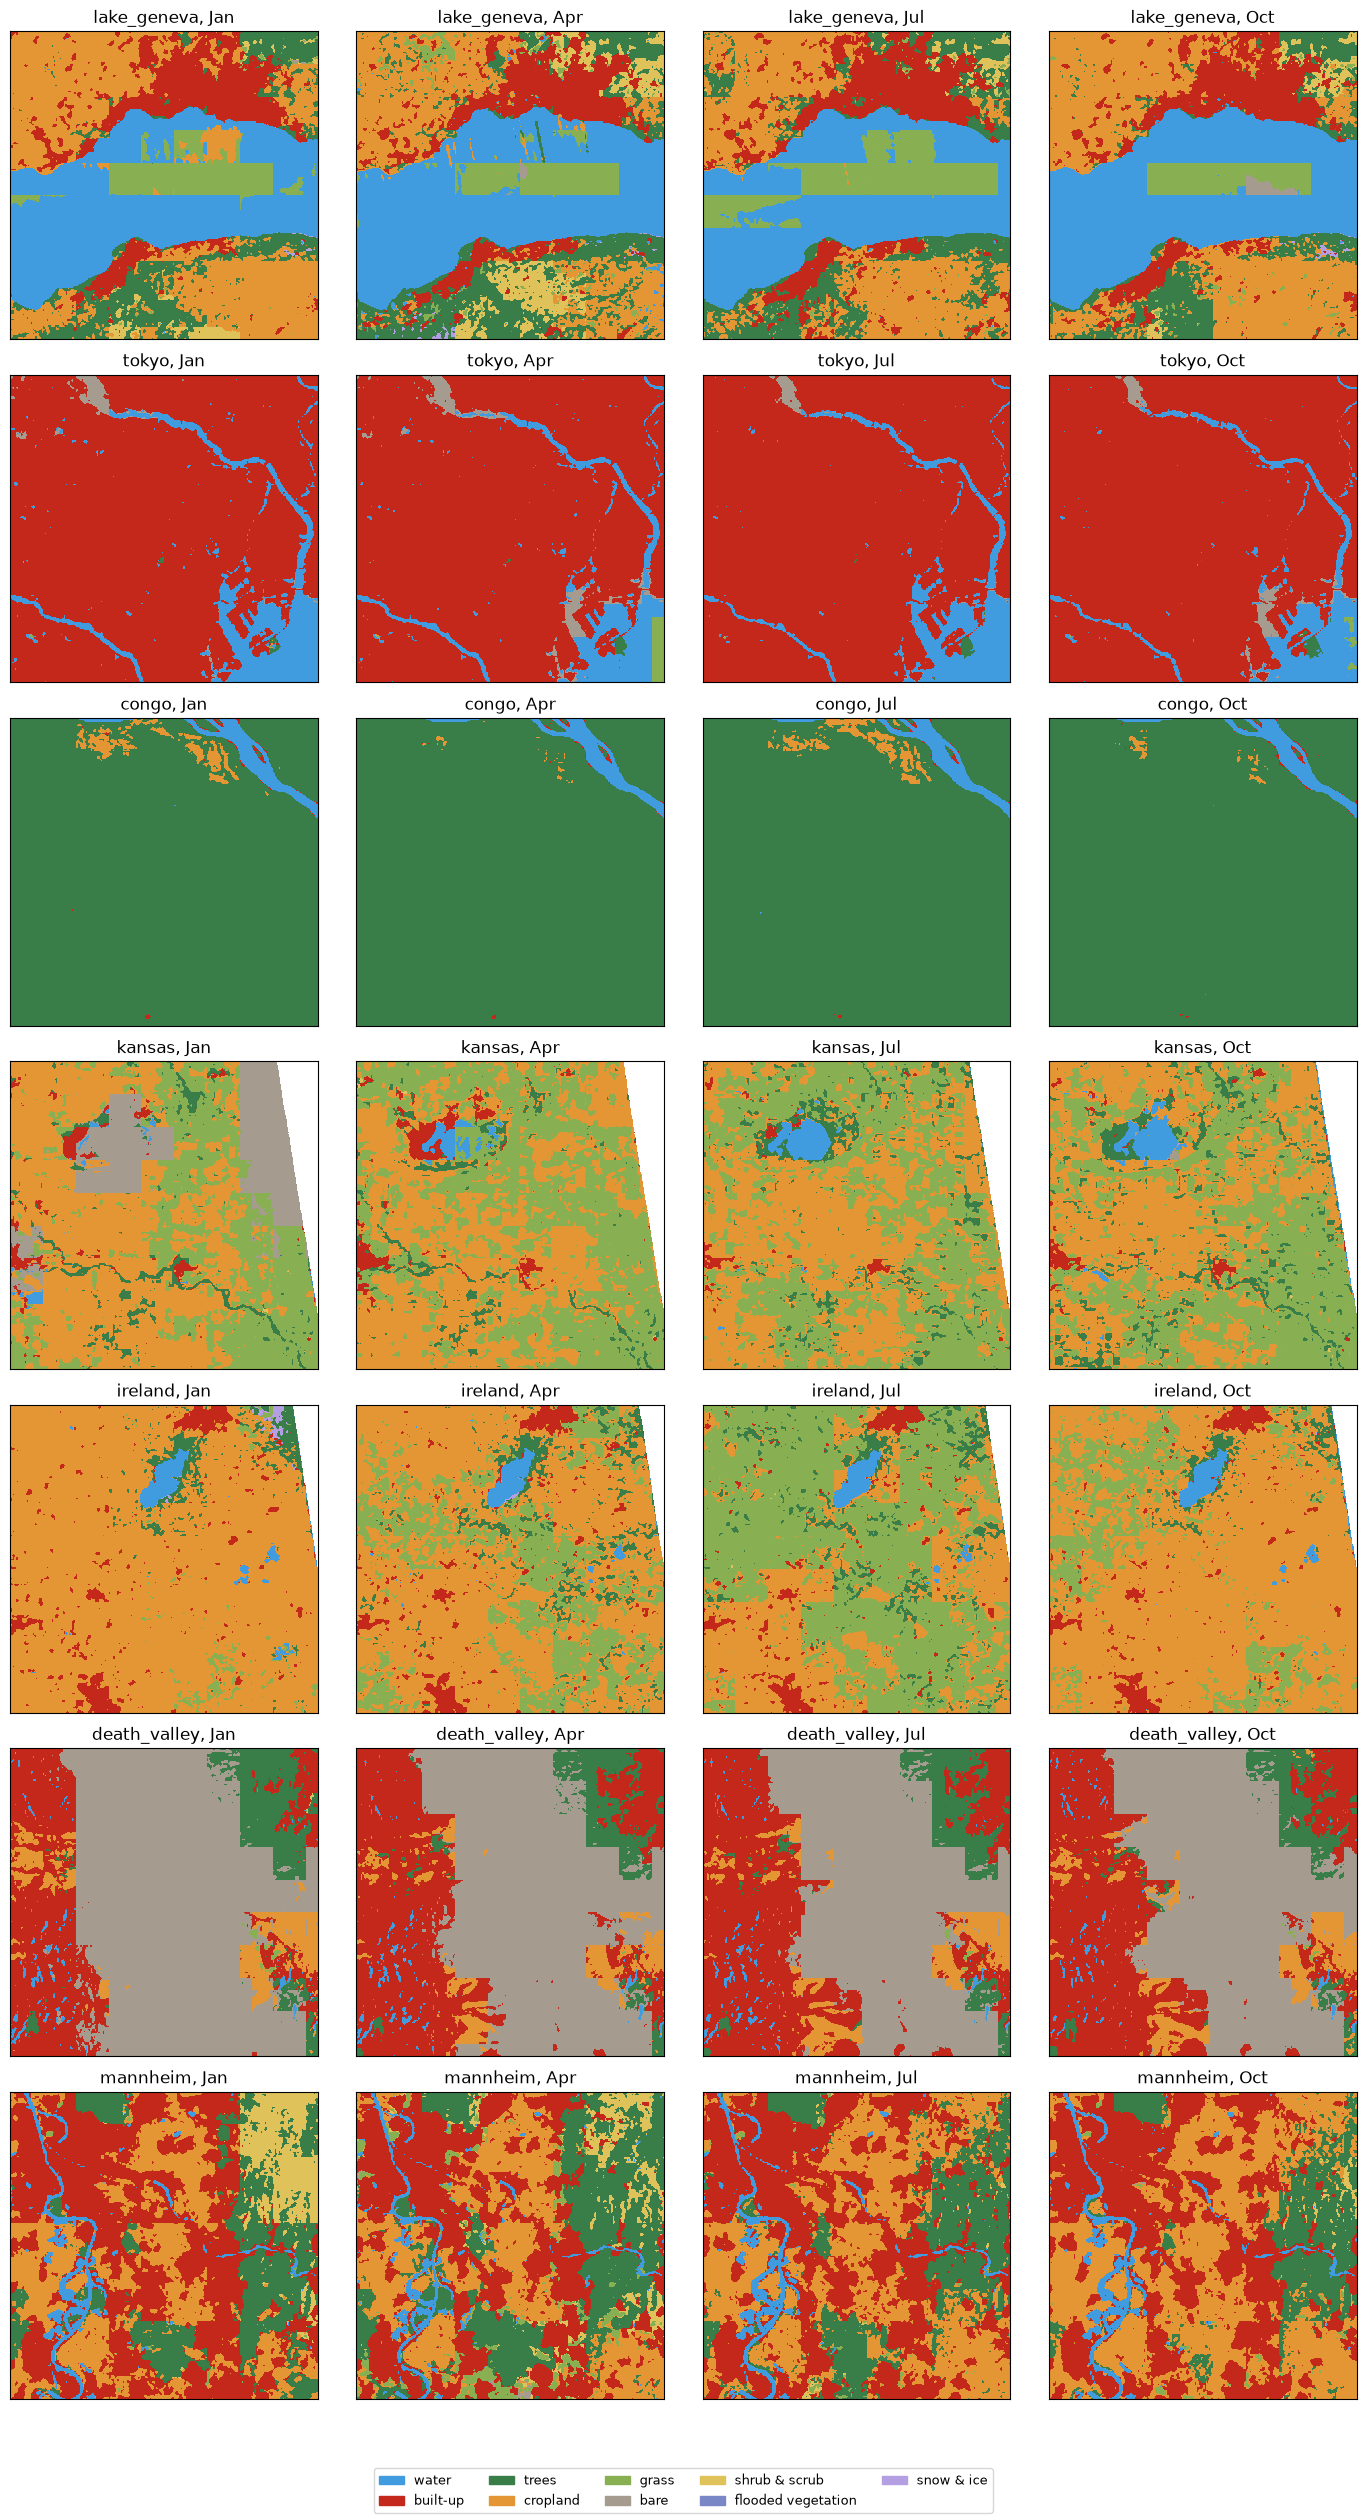

In [23]:
palette = ListedColormap(COLOURS)
pick = [0, 3, 6, 9]                      # Jan, Apr, Jul, Oct
fig, axes = plt.subplots(len(maps), 4, figsize=(14, 3.6 * len(maps)), squeeze=False)
for row, aoi in zip(axes, maps):
    for ax, m in zip(row, pick):
        ax.imshow(maps[aoi][m], cmap=palette, vmin=0, vmax=config.NUM_CLASSES - 1, interpolation="nearest")
        ax.set_title(f"{aoi}, {SHORT[m]}"); ax.set_xticks([]); ax.set_yticks([])
fig.legend(handles=[Patch(color=COLOURS[c], label=config.CLASSES[c]) for c in CLASS_IDS],
           loc="lower center", ncol=5, fontsize=9)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

## The check - does Dynamic World see the same change?

Dynamic World, made from the optical satellite, is an independent instrument: if its monthly curve rises and falls with the radar model's, the change is real and not the model's invention.

In [24]:
DW_NAMES = ["water", "trees", "grass", "flooded_vegetation", "crops",
            "shrub_and_scrub", "built", "bare", "snow_and_ice"]        # export order = DW class + 1
TO_OURS = {name: config.DW_CLASS_MAP[i + 1] for i, name in enumerate(DW_NAMES)}


def number(text):
    try:
        return float(text)
    except (TypeError, ValueError):
        return np.nan                     # an empty cell = a month with nothing seen


dw, dw_cover = {}, {}
if not DW_CSV.exists():
    print(f"No {DW_CSV.relative_to(config.ROOT)} yet. Run labelling/gee/export_dw_monthly.js in")
    print("Earth Engine, download the CSV from the echoscape_dw Drive folder to that path, re-run this cell.")
else:
    with open(DW_CSV, newline="") as handle:
        for row in csv.DictReader(handle):
            aoi, month = row["region"], row["month"]
            if aoi not in shares or month not in MONTHS:
                continue
            i = MONTHS.index(month)
            dw.setdefault(aoi, np.full((12, config.NUM_CLASSES), np.nan))
            dw_cover.setdefault(aoi, np.zeros(12))
            dw_cover[aoi][i] = number(row["coverage"])
            for name in DW_NAMES:
                dw[aoi][i, TO_OURS[name]] = 100 * number(row[name])
    print(f"Dynamic World monthly shares read for {len(dw)} of {len(shares)} regions")

Dynamic World monthly shares read for 7 of 7 regions


In [25]:
def agreement(a, b):
    """Do two monthly curves rise and fall together? Correlation of their shapes,
    only where both actually move - a flat line has no shape to agree with."""
    if len(a) < 6 or np.ptp(a) < NOISE or np.ptp(b) < NOISE:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])


report = {}
if dw:
    print(f"{'region':<14}{'class':<20}{'radar swing':>12}{'DW swing':>10}{'same shape?':>13}{'mean gap':>10}")
    print("-" * 79)
    for aoi in dw:
        good = dw_cover[aoi] >= MIN_DW_COVER
        for c in shown(aoi):
            a, b = shares[aoi][good, c], dw[aoi][good, c]
            r = agreement(a, b)
            report[(aoi, c)] = r
            shape = "-" if np.isnan(r) else f"r = {r:+.2f}"
            print(f"{aoi:<14}{config.CLASSES[c]:<20}{np.ptp(shares[aoi][:, c]):>10.1f}pt"
                  f"{np.nanmax(b) - np.nanmin(b) if good.any() else np.nan:>8.1f}pt{shape:>13}"
                  f"{np.nanmean(np.abs(a - b)) if good.any() else np.nan:>8.1f}pt")
        if (~good).any():
            print(f"{'':<14}(left out, Dynamic World saw under {MIN_DW_COVER:.0%} of the box: "
                  f"{', '.join(SHORT[i] for i in np.where(~good)[0])})")
    print("\nr near +1: both instruments see the same seasonal rise and fall - the change is real.")
    print("r near 0 or negative: they disagree - treat that class's monthly change with suspicion.")
    print("'-': one of the two curves is flat (within the noise), so there is no shape to compare.")

region        class                radar swing  DW swing  same shape?  mean gap
-------------------------------------------------------------------------------
mannheim      water                      1.4pt     4.6pt            -     1.1pt
mannheim      built-up                  11.3pt    22.1pt    r = -0.67    10.4pt
mannheim      trees                     16.2pt    28.3pt    r = +0.11    13.7pt
mannheim      cropland                  20.6pt    19.7pt    r = +0.37     7.6pt
mannheim      grass                      4.2pt     5.7pt            -     2.4pt
mannheim      shrub & scrub             10.3pt     1.9pt            -     3.5pt
              (left out, Dynamic World saw under 50% of the box: Aug, Oct, Nov, Dec)
lake_geneva   water                      6.2pt    14.4pt            -     9.3pt
lake_geneva   built-up                   3.7pt     9.9pt            -     1.8pt
lake_geneva   trees                      7.8pt    15.3pt    r = -0.44     7.1pt
lake_geneva   cropland             

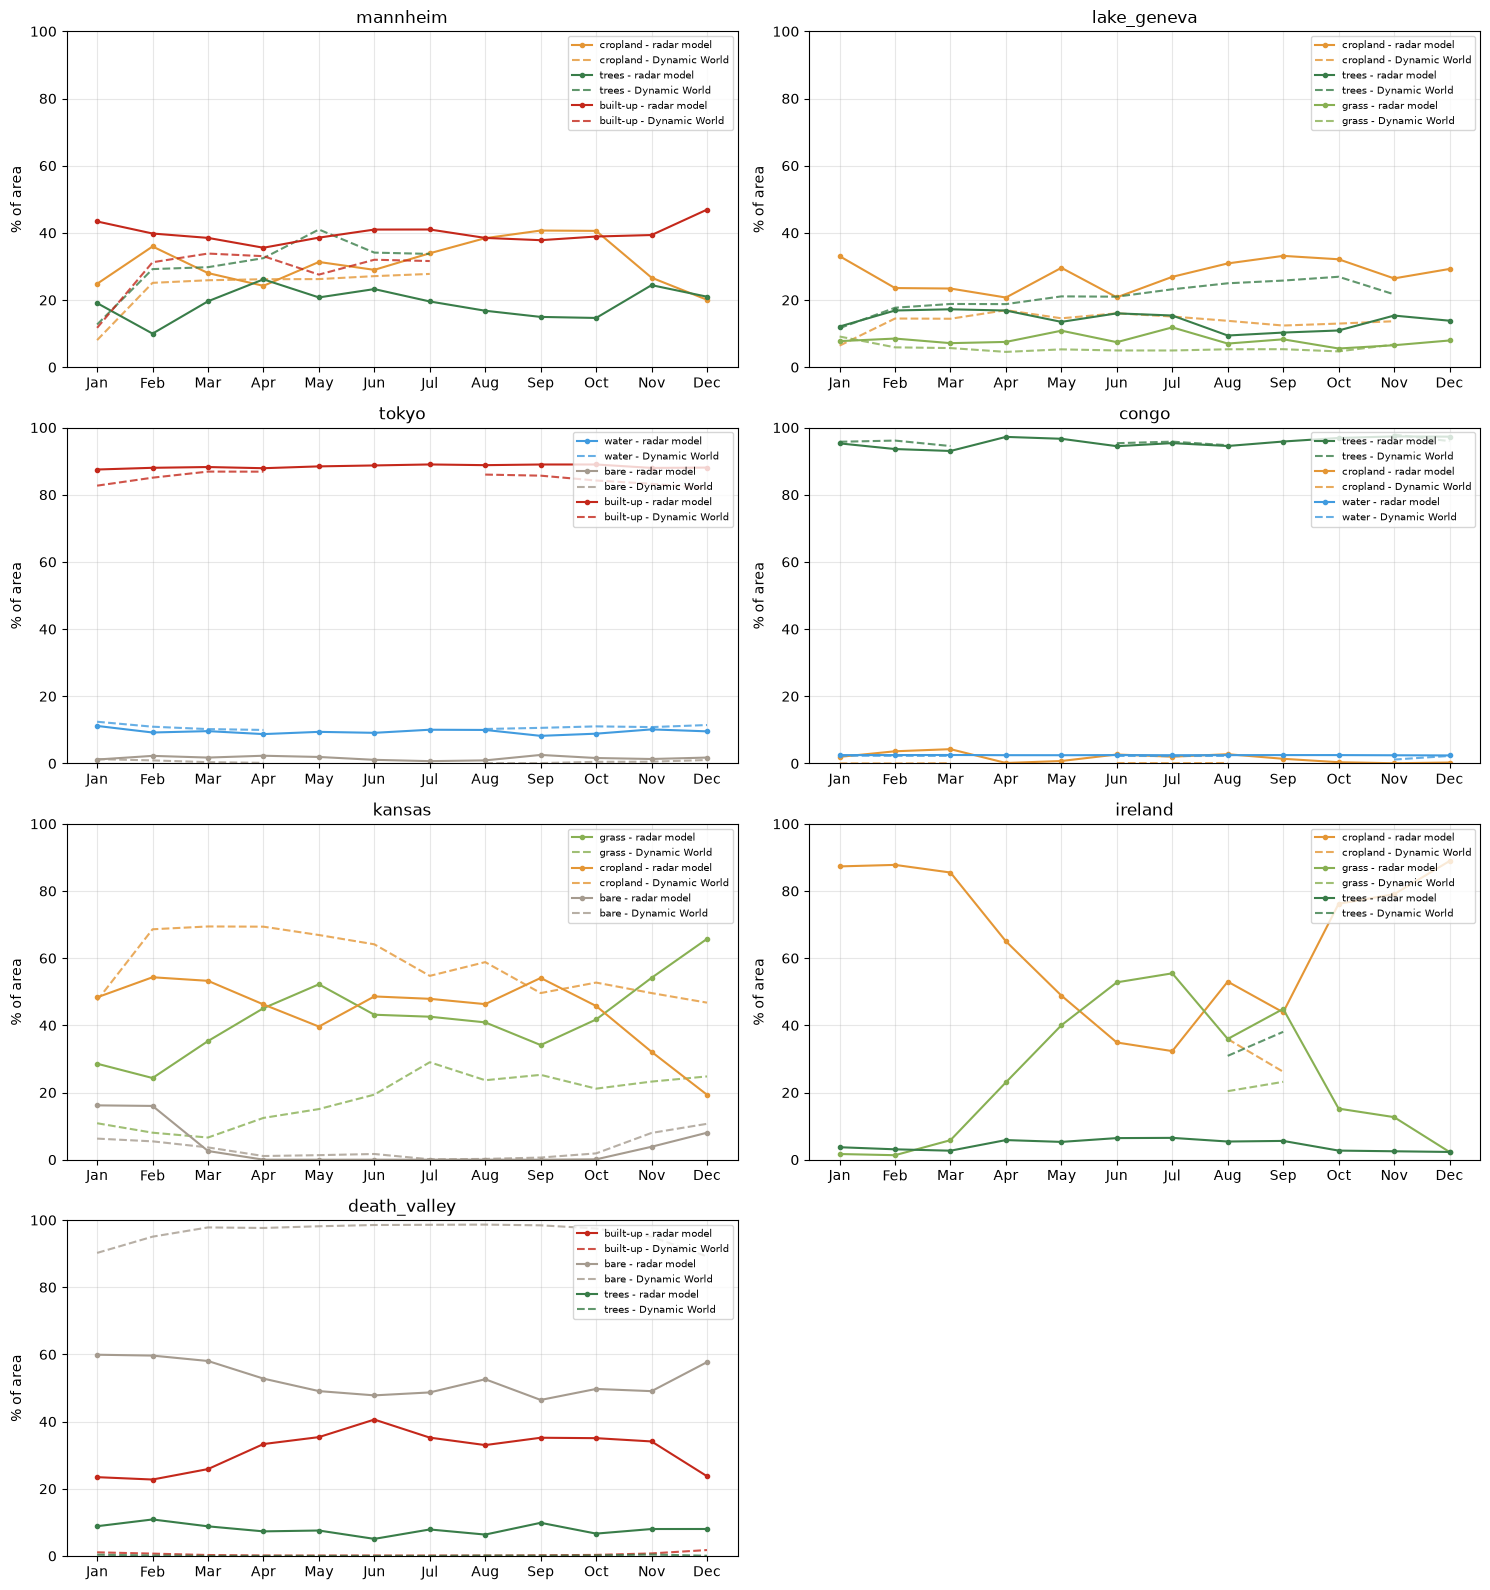

Solid = what the radar model sees, dashed = what the optical Dynamic World sees.
Gaps in a dashed line are months too cloudy for the optical satellite - the radar has no such gaps.


In [26]:
if dw:
    rows = int(np.ceil(len(dw) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(15, 4 * rows), squeeze=False)
    for ax, aoi in zip(axes.ravel(), dw):
        good = dw_cover[aoi] >= MIN_DW_COVER
        top = sorted(shown(aoi), key=lambda c: -np.ptp(shares[aoi][:, c]))[:3]   # the three that move most
        for c in top:
            ax.plot(range(12), shares[aoi][:, c], "-o", ms=3, color=COLOURS[c], label=f"{config.CLASSES[c]} - radar model")
            dw_line = np.where(good, dw[aoi][:, c], np.nan)
            ax.plot(range(12), dw_line, "--", color=COLOURS[c], alpha=0.8, label=f"{config.CLASSES[c]} - Dynamic World")
        ax.set_xticks(range(12)); ax.set_xticklabels(SHORT); ax.set_ylim(0, 100); ax.grid(alpha=0.3)
        ax.set_ylabel("% of area"); ax.set_title(aoi); ax.legend(fontsize=7, loc="upper right")
    for ax in axes.ravel()[len(dw):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()
    print("Solid = what the radar model sees, dashed = what the optical Dynamic World sees.")
    print("Gaps in a dashed line are months too cloudy for the optical satellite - the radar has no such gaps.")

## Findings

Filled in once the notebook has run on the final model.

| region | biggest change | from | to | above noise? | Dynamic World agrees? |
|---|---|---|---|---|---|
| | | | | | |